# NB5a conformal — calibrated intervals from pseudo cold starts (validation units only)

D06, guide §6 item 14, D35. NB5a found the 80% intervals too narrow (coverage 0.63–0.71, F40): the composition carries the index and gain uncertainty but not the target roof's own deviation from the fleet. Reads `results/nb5a_dev/`; writes `results/nb5a_conformal/`. No test event is used.

**Rules fixed before any number below:**
1. *Calibration set*, per event, origin and horizon: pseudo cold starts of the event's donors (clean-metadata donors for a G1/G2 target, all donors for a G0 target). Their index is forecast by the early-stopped LightGBM models on the last 20% of the training pairs (out of sample for those models, targets before the origin) and composed with each donor's leave-one-out prior and uncertainty set (200 members, the main model's levels).
2. *Conformity*: CQR (Romano et al. 2019) per horizon and per central interval (80, 60, 40 and 20%), normalised by G̃(t + h). The correction is the ⌈(1 − α)(n + 1)⌉-th smallest score; under 50 scores, none.
3. *Use*: applied to the main model's 9 power quantiles; the median and the point forecast are unchanged.
4. *Keep rule*: the layer is kept if, on the validation units (true cold starts, never in their own donor set), it brings the median PICP80 at 1 h closer to 0.80 than the raw forecast and does not raise the median IS80 at 1 h.

In [1]:
import os, sys, time, json, hashlib
from pathlib import Path
import numpy as np, pandas as pd, yaml
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if ROOT.name == 'notebooks' else ROOT
sys.path.insert(0, str(ROOT / 'src'))
os.environ['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + os.environ.get('PYTHONPATH', '')
os.environ.setdefault('LOKY_MAX_CPU_COUNT', str(os.cpu_count()))
from joblib import Parallel, delayed
from pvcold import config as C, audit as A, fleet as F, forecast as FC
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 40)
N_JOBS = os.cpu_count(); t0 = time.time()
nb5 = json.loads((C.RESULTS / 'nb5a_dev' / 'summary.json').read_text())
LGB_TEXT = (C.RESULTS / 'nb5a_dev' / 'lgb_config_part2a.yaml').read_bytes().decode('utf-8')
assert hashlib.sha256(LGB_TEXT.encode()).hexdigest() == nb5['lgb_config_sha256'], 'LightGBM config changed'
LGB_PARAMS = yaml.safe_load(LGB_TEXT)['lgb_params']
PRIOR = yaml.safe_load((C.RESULTS / 'nb3_index' / 'frozen_config_part1.yaml').read_text())['prior_variant']
ALT = json.loads((C.RESULTS / 'nb1_audit' / 'summary.json').read_text())['campus_altitude_m']
p = F.load_panel(); del p['targets15_kW']
E = p['events'].set_index('event'); U = p['units']; geo15 = p['geometry15']
VAL = E.index[E.set == 'validation'].tolist()
idx = {k: pd.read_parquet(C.RESULTS / 'nb3_index' / f'{k}.parquet').set_index('time') for k in ['k_cens', 'sigma', 'c', 'n']}
gains3 = pd.read_csv(C.RESULTS / 'nb3_index' / 'gains.csv')
fc5 = pd.read_parquet(C.RESULTS / 'nb5a_dev' / 'val_forecasts.parquet')
QC = [f'q{t:.1f}' for t in FC.TAUS]
lv, gl = FC.member_levels()
print('LightGBM setting:', LGB_PARAMS, '| prior', PRIOR, '| NB5a forecast rows', len(fc5))

LightGBM setting: {'learning_rate': 0.05, 'min_data_in_leaf': 200, 'num_leaves': 31} | prior G2 | NB5a forecast rows 1287874


## Calibration sets: the LightGBM bank refitted with its out-of-sample predictions
The forecasts must equal NB5a's (same code path, same seed).

In [2]:
tasks = []
for v in VAL:
    s = E.loc[v, 'start']; S = FC.event_series(v, idx, geo15)
    for d in FC.ORIGIN_DAYS:
        o = s + pd.Timedelta(days=d)
        tasks.append((v, S, o, min(o + pd.Timedelta(days=30), s + pd.Timedelta(days=90))))
t1 = time.time()
res = Parallel(n_jobs=N_JOBS)(delayed(FC.cal_task)(v, S, o, e, LGB_PARAMS) for v, S, o, e in tasks)
lgb = pd.concat([r[2] for r in res], ignore_index=True); cal = pd.concat([r[3] for r in res], ignore_index=True)
key = ['event', 'origin', 'h', 't']
m = lgb.merge(fc5[fc5.model == 'LGB'], on=key, suffixes=('', '_nb5a'))
diff = float(np.abs(m[QC].to_numpy() - m[[c + '_nb5a' for c in QC]].to_numpy()).max())
print('%d tasks in %.0f s | LightGBM rows %d (NB5a %d), max |diff| vs NB5a %.1e | calibration rows %d'
      % (len(tasks), time.time() - t1, len(lgb), int((fc5.model == 'LGB').sum()), diff, len(cal)))
assert len(m) == len(lgb) == int((fc5.model == 'LGB').sum()) and diff < 1e-5

30 tasks in 316 s | LightGBM rows 183982 (NB5a 183982), max |diff| vs NB5a 6.0e-08 | calibration rows 82273


## Conformity scores of the donors' pseudo cold starts, and the corrections

In [3]:
Tcache, crow, ev_gain = {}, [], {}
for v in VAL:
    a = F.event_arrays(v, p)
    g = gains3[gains3.event == v].set_index('donor')['gain'].reindex(a['dn'])
    pr, T_don, r_don, meta_ok = F.event_priors(a, g, U, ALT, Tcache)
    variant = PRIOR if pr['target_in_prior_test'] else 'G0'
    B = np.asarray(pr['B_' + variant]) if variant != 'G0' else g.dropna().to_numpy()
    ev_gain[v] = FC.gain_members(pr[variant], B / np.median(B), gl)
    pp = FC.pseudo_priors(g, r_don, T_don, meta_ok, variant)
    for (o, h), x in cal[cal.event == v].groupby(['origin', 'h']):
        tgt = x['t'] + pd.Timedelta(minutes=15 * h)
        gtt = geo15['Gt'].reindex(tgt).to_numpy(); Qi = x[QC].to_numpy()
        Es = []
        for d, (g0, Brel) in pp.items():
            yd = p['y15'][d].reindex(tgt).to_numpy(); ok = np.isfinite(yd)
            Y = FC.power_members(Qi[ok], gtt[ok], FC.gain_members(g0, Brel, gl), lv)
            Es.append(FC.conformity(FC.power_quantiles(Y), yd[ok], gtt[ok]))
        Eall = np.vstack(Es)
        corr = FC.conformal_correction(Eall)
        crow.append({'event': v, 'origin': o, 'h': h, 'variant': variant, 'n_donors': len(pp), 'n_scores': len(Eall),
                     'cal_days': int(x['t'].dt.normalize().nunique()),
                     **{f'raw_cover{n}': float(np.mean(Eall[:, j] <= 0)) for j, n in enumerate(FC.PAIR_NAMES)},
                     **{f'corr{n}': float(corr[j]) for j, n in enumerate(FC.PAIR_NAMES)}})
corrs = pd.DataFrame(crow)
print('raw coverage of the pseudo cold starts and corrections (median over units and origins):')
print(corrs.groupby('h')[[c for c in corrs.columns if c.startswith(('raw_cover', 'corr', 'n_scores', 'cal_days'))]].median().round(3).to_string())
print('groups with fewer than %d scores (no correction): %d of %d' % (FC.MIN_CAL, int((corrs.n_scores < FC.MIN_CAL).sum()), len(corrs)))

raw coverage of the pseudo cold starts and corrections (median over units and origins):
    n_scores  cal_days  raw_cover80  raw_cover60  raw_cover40  raw_cover20  corr80  corr60  corr40  corr20
h                                                                                                         
1     6806.0      12.0        0.722        0.528        0.325        0.154   0.027   0.014   0.011   0.007
2     6647.0      12.0        0.711        0.536        0.345        0.153   0.042   0.018   0.012   0.008
4     6344.0      12.0        0.714        0.509        0.327        0.153   0.047   0.032   0.019   0.011
8     5738.0      12.0        0.699        0.510        0.348        0.159   0.061   0.030   0.016   0.015
16    4526.0      12.0        0.691        0.500        0.317        0.144   0.066   0.038   0.033   0.027
24    3387.0      12.0        0.650        0.467        0.295        0.150   0.076   0.062   0.043   0.024
groups with fewer than 50 scores (no correction): 0 of 1

## Validation units (true cold starts): raw against conformal intervals
Same scored slots as NB5a (every model has a forecast and the observation exists).

In [4]:
MODELS5 = sorted(fc5.model.unique())
cidx = corrs.set_index(['event', 'origin', 'h'])
srows = []
for v in VAL:
    assert E.loc[v, 'set'] == 'validation'      # target power is read for validation units only
    f = fc5[fc5.event == v].copy()
    f['target'] = f['t'] + pd.to_timedelta(15 * f['h'], unit='min')
    f['y'] = p['y15'][E.loc[v, 'units']].reindex(f['target']).to_numpy()
    f['gt'] = geo15['Gt'].reindex(f['target']).to_numpy()
    good = f[QC].notna().all(axis=1) & np.isfinite(f['y'])
    cnt = f[good].groupby(['h', 't'])['model'].nunique()
    keep = cnt[cnt == len(MODELS5)].index
    f = f[f.model == 'LGB'].set_index(['h', 't']).loc[lambda x: x.index.isin(keep)].reset_index()
    for h, xh in f.groupby('h'):
        parts = {'raw': [], 'conformal': []}; ys, tm = [], []
        for o, x in xh.groupby('origin'):
            gt_ = x['gt'].to_numpy()
            Qp = FC.power_quantiles(FC.power_members(x[QC].to_numpy(dtype=float), gt_, ev_gain[v], lv))
            corr = cidx.loc[(v, o, h), [f'corr{n}' for n in FC.PAIR_NAMES]].to_numpy(dtype=float)
            parts['raw'].append(Qp); parts['conformal'].append(FC.apply_conformal(Qp, gt_, corr))
            ys.append(x['y'].to_numpy()); tm.append((x['target'].dt.hour * 60 + x['target'].dt.minute).to_numpy())
        y_, tm_ = np.concatenate(ys), np.concatenate(tm)
        for kind, Qs in parts.items():
            Qa = np.vstack(Qs)
            for win, msk in [('full', np.ones(len(y_), bool)), ('common', tm_ >= FC.COMMON_WINDOW_MIN)]:
                srows.append({'event': v, 'h': h, 'kind': kind, 'window': win, **FC.quantile_scores(Qa[msk], y_[msk], lv)})
vs = pd.DataFrame(srows)
nb5_picp = pd.read_csv(C.RESULTS / 'nb5a_dev' / 'val_scores.csv').query("model == 'LGB' and window == 'full'").set_index(['event', 'h'])['PICP80']
chk = vs[(vs.kind == 'raw') & (vs.window == 'full')].set_index(['event', 'h'])['cover80']
print('raw PICP80 equals NB5a: max |diff| = %.1e' % float((chk - nb5_picp.reindex(chk.index)).abs().max()))
MET = ['cover80', 'cover60', 'cover40', 'cover20', 'PINAW', 'IS80', 'CRPS_q']
vm = vs.groupby(['window', 'kind', 'h'])[MET].median().reset_index()
for met in MET:
    print(f'median {met}, full window:'); print(vm[vm.window == 'full'].pivot(index='kind', columns='h', values=met).round(4).to_string())

raw PICP80 equals NB5a: max |diff| = 0.0e+00
median cover80, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.7858  0.8031  0.7965  0.7525  0.7780  0.7775
raw        0.6846  0.6978  0.7142  0.6624  0.6286  0.6489
median cover60, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.5966  0.6209  0.6184  0.5613  0.5598  0.6081
raw        0.5046  0.5042  0.5111  0.4878  0.4638  0.4671
median cover40, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.3944  0.3978  0.3981  0.3628  0.3683  0.4191
raw        0.3153  0.3148  0.3255  0.3045  0.2994  0.3126
median cover20, full window:
h              1       2       4       8       16      24
kind                                                     
conformal  0.1849  0.1924  

## Keep rule (rule 4)

In [5]:
r1 = vm[(vm.window == 'full') & (vm.h == C.PRIMARY_HORIZON)].set_index('kind')
closer = abs(r1.loc['conformal', 'cover80'] - 0.8) < abs(r1.loc['raw', 'cover80'] - 0.8)
not_worse = r1.loc['conformal', 'IS80'] <= r1.loc['raw', 'IS80']
KEEP = bool(closer and not_worse)
won = vs[(vs.window == 'full') & (vs.h == C.PRIMARY_HORIZON)].pivot(index='event', columns='kind', values='IS80')
print('at 1 h: PICP80 raw %.3f -> conformal %.3f | IS80 raw %.4f -> conformal %.4f | units with lower IS80: %d of %d'
      % (r1.loc['raw', 'cover80'], r1.loc['conformal', 'cover80'], r1.loc['raw', 'IS80'], r1.loc['conformal', 'IS80'],
         int((won['conformal'] < won['raw']).sum()), len(won)))
print('KEEP the conformal layer:', KEEP)

at 1 h: PICP80 raw 0.714 -> conformal 0.797 | IS80 raw 0.5739 -> conformal 0.5716 | units with lower IS80: 8 of 10
KEEP the conformal layer: True


## Draft figure: reliability of the central intervals

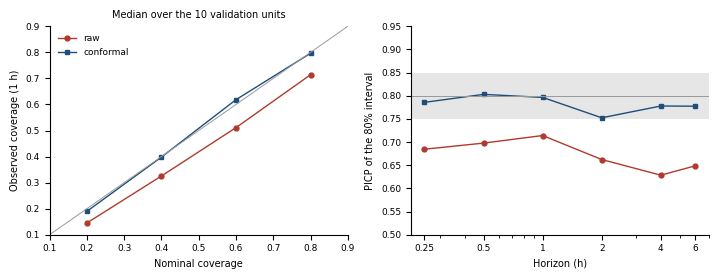

In [6]:
import matplotlib.pyplot as plt
A._style()
f7, ax = plt.subplots(1, 2, figsize=(7.2, 2.8))
nom = np.array([0.2, 0.4, 0.6, 0.8])
for kind, c, mk in [('raw', '#b03a2e', 'o'), ('conformal', '#1f4e79', 's')]:
    r = vm[(vm.window == 'full') & (vm.kind == kind) & (vm.h == C.PRIMARY_HORIZON)].iloc[0]
    ax[0].plot(nom, [r['cover20'], r['cover40'], r['cover60'], r['cover80']], marker=mk, ms=3.5, color=c, lw=1, label=kind)
    z = vm[(vm.window == 'full') & (vm.kind == kind)].set_index('h').loc[FC.H, 'cover80']
    ax[1].plot(np.array(FC.H) * 0.25, z, marker=mk, ms=3.5, color=c, lw=1, label=kind)
ax[0].plot([0, 1], [0, 1], color='0.6', lw=0.7); ax[0].set_xlim(0.1, 0.9); ax[0].set_ylim(0.1, 0.9)
ax[0].set_xlabel('Nominal coverage'); ax[0].set_ylabel('Observed coverage (1 h)'); ax[0].legend(frameon=False)
ax[1].axhspan(0.75, 0.85, color='0.9', lw=0); ax[1].axhline(0.8, color='0.6', lw=0.7)
ax[1].set_xscale('log'); ax[1].set_xticks(np.array(FC.H) * 0.25); ax[1].set_xticklabels(['0.25', '0.5', '1', '2', '4', '6'])
ax[1].set_xlabel('Horizon (h)'); ax[1].set_ylabel('PICP of the 80% interval'); ax[1].set_ylim(0.5, 0.95)
ax[0].set_title('Median over the 10 validation units', fontsize=7); f7.tight_layout()

## Outputs (all-or-nothing); the conformal settings join the frozen part 2

In [7]:
conf_cfg = {'part': '2b', 'lgb_config': nb5['lgb_config_sha256'], 'method': 'CQR (Romano et al. 2019), split conformal',
            'calibration_set': 'pseudo cold starts of the event donors, early-stopped LightGBM predictions on the last 20% of the training pairs',
            'donors': 'clean metadata (G1/G2 target) or all (G0 target); leave-one-out prior and uncertainty set',
            'intervals': FC.PAIR_NAMES, 'normalisation': 'Gt(t + h)', 'per': 'event, origin, horizon',
            'min_scores': FC.MIN_CAL, 'power_bounds': list(FC.POWER_BOUNDS), 'median_and_point': 'unchanged',
            'keep_rule': 'median PICP80 at 1 h closer to 0.80 and median IS80 at 1 h not higher (validation units)',
            'kept': KEEP}
CONF_TEXT = yaml.safe_dump(conf_cfg, sort_keys=True)
CONF_HASH = hashlib.sha256(CONF_TEXT.encode()).hexdigest()
full = vm[vm.window == 'full']
summary = {'notebook': 'NB5a_conformal', 'environment': A.versions(), 'runtime_s': round(time.time() - t0, 1),
           'lgb_config_sha256': nb5['lgb_config_sha256'], 'conformal_config_sha256': CONF_HASH, 'kept': KEEP,
           'lgb_rows_max_abs_diff_vs_nb5a': diff, 'groups_without_correction': int((corrs.n_scores < FC.MIN_CAL).sum()),
           'median_corrections_by_h': corrs.groupby('h')[[f'corr{n}' for n in FC.PAIR_NAMES]].median().round(4).to_dict('index'),
           'pseudo_raw_cover80_by_h': corrs.groupby('h')['raw_cover80'].median().round(4).to_dict(),
           **{f'{kind}_{met}_by_h': full[full.kind == kind].set_index('h')[met].round(4).to_dict()
              for kind in ['raw', 'conformal'] for met in ['cover80', 'PINAW', 'IS80', 'CRPS_q']}}
out = A.write_outputs('nb5a_conformal', {'corrections': corrs, 'val_conformal_scores': vs, 'val_conformal_medians': vm},
                      summary, {'fig_conformal_reliability': f7}, parquet={'calibration_quantiles': cal},
                      texts={'conformal_config_part2b.yaml': CONF_TEXT})
print('conformal config (part 2b) sha256:', CONF_HASH)
print('written to', out, '|', sorted(x.name for x in out.iterdir()))

conformal config (part 2b) sha256: c68d5a3aa17a680621d60f1edc924997ec8955923f588e5fbbc41109cd0b8c9e
written to C:\Users\Dell\Desktop\phd_ehtp\pv paper\results\nb5a_conformal | ['calibration_quantiles.parquet', 'conformal_config_part2b.yaml', 'corrections.csv', 'figures', 'summary.json', 'val_conformal_medians.csv', 'val_conformal_scores.csv']
